In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('imdb_top_1000.csv')
df.head()

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


In [7]:
"""  
Data:-

Poster_Link - Link of the poster that imdb using
Series_Title = Name of the movie
Released_Year - Year at which that movie released
Certificate - Certificate earned by that movie
Runtime - Total runtime of the movie
Genre - Genre of the movie
IMDB_Rating - Rating of the movie at IMDB site
Overview - mini story/ summary
Meta_score - Score earned by the movie
Director - Name of the Director
Star1,Star2,Star3,Star4 - Name of the Stars
No_of_votes - Total number of votes
Gross - Money earned by that movie



""";

In [4]:
df.shape

(1000, 16)

In [5]:
df.columns

Index(['Poster_Link', 'Series_Title', 'Released_Year', 'Certificate',
       'Runtime', 'Genre', 'IMDB_Rating', 'Overview', 'Meta_score', 'Director',
       'Star1', 'Star2', 'Star3', 'Star4', 'No_of_Votes', 'Gross'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   str    
 1   Series_Title   1000 non-null   str    
 2   Released_Year  1000 non-null   str    
 3   Certificate    899 non-null    str    
 4   Runtime        1000 non-null   str    
 5   Genre          1000 non-null   str    
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   str    
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   str    
 10  Star1          1000 non-null   str    
 11  Star2          1000 non-null   str    
 12  Star3          1000 non-null   str    
 13  Star4          1000 non-null   str    
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    str    
dtypes: float64(2), int64(1), str(13)
memory usage: 520.0 KB


In [9]:
# check the missing values
# also see the percentage of missing values

In [12]:
df.isnull().sum().sort_values()

Poster_Link        0
Series_Title       0
Released_Year      0
Runtime            0
IMDB_Rating        0
Genre              0
Overview           0
Director           0
No_of_Votes        0
Star1              0
Star2              0
Star3              0
Star4              0
Certificate      101
Meta_score       157
Gross            169
dtype: int64

In [13]:
missing_pct = df.isnull().mean() * 100
missing_pct

Poster_Link       0.0
Series_Title      0.0
Released_Year     0.0
Certificate      10.1
Runtime           0.0
Genre             0.0
IMDB_Rating       0.0
Overview          0.0
Meta_score       15.7
Director          0.0
Star1             0.0
Star2             0.0
Star3             0.0
Star4             0.0
No_of_Votes       0.0
Gross            16.9
dtype: float64

In [15]:
# check for duplicate rows -> no. of rows
# check for duplicate titles -> no. of titles

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df['Series_Title'].duplicated().sum()

np.int64(1)

In [18]:
# remove the unneeded col -> Poster_Link  

In [19]:
df.columns

Index(['Poster_Link', 'Series_Title', 'Released_Year', 'Certificate',
       'Runtime', 'Genre', 'IMDB_Rating', 'Overview', 'Meta_score', 'Director',
       'Star1', 'Star2', 'Star3', 'Star4', 'No_of_Votes', 'Gross'],
      dtype='str')

In [21]:
df.drop('Poster_Link', axis = 1, inplace= True)

In [22]:
# check why year is coming as str ? convert to numerical

In [23]:
df['Released_Year'].value_counts()

Released_Year
2014    32
2004    31
2009    29
2016    28
2013    28
        ..
1920     1
1930     1
1922     1
1943     1
PG       1
Name: count, Length: 100, dtype: int64

In [25]:
df[pd.to_numeric(df['Released_Year'], errors= 'coerce').isnull()]

,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
966,Apollo 13,PG,U,140 min,"Adventure, Drama, History",7.6,NASA must devise a strategy to return Apollo 1...,77.0,Ron Howard,Tom Hanks,Bill Paxton,Kevin Bacon,Gary Sinise,269197,"173,837,933"


In [26]:
# check on the internet when the Apollo 13 was released and fill the value

In [29]:
df.loc[966, 'Released_Year'] = '1995'

In [30]:
df['Released_Year'] = df['Released_Year'].astype(int)

In [31]:
df['Released_Year'].dtype

dtype('int64')

In [32]:
df.head()

,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


In [33]:
# in the runtime col -> remove that 'min' and convert the column to int

In [34]:
df['Runtime'] = df['Runtime'].str.replace(' min', '').astype(int)
df['Runtime'].describe()

count    1000.000000
mean      122.891000
std        28.093671
min        45.000000
25%       103.000000
50%       119.000000
75%       137.000000
max       321.000000
Name: Runtime, dtype: float64

In [35]:
# fix Gross column -> remove the commas from the values and convert it to float

In [37]:
df['Gross'] = df['Gross'].str.replace(',', '').astype(float)
df['Gross'].describe()

count    8.310000e+02
mean     6.803475e+07
std      1.097500e+08
min      1.305000e+03
25%      3.253559e+06
50%      2.353089e+07
75%      8.075089e+07
max      9.366622e+08
Name: Gross, dtype: float64

In [38]:
# for filling missing values 
# meta score -> median, gross -> median, certificate -> Unknown

In [40]:
import warnings
warnings.filterwarnings('ignore')

In [44]:
df['Meta_score'] = df['Meta_score'].fillna(df['Meta_score'].median())
df['Gross'] = df['Gross'].fillna(df['Gross'].median())
df['Certificate'] = df['Certificate'].fillna('Unknown')

In [45]:
df['Gross'].isnull().sum()

np.int64(0)

In [46]:
# add the new col -> gross_m (gross value in millions)

In [47]:
# check the distribution (univariate analysis) -> imdb rating, runtime, gross

In [48]:
df['Gross_m'] = df['Gross']/1000000
df['Gross_m']

0       28.341469
1      134.966411
2      534.858444
3       57.300000
4        4.360000
          ...    
995     23.530892
996     23.530892
997     30.500000
998     23.530892
999     23.530892
Name: Gross_m, Length: 1000, dtype: float64

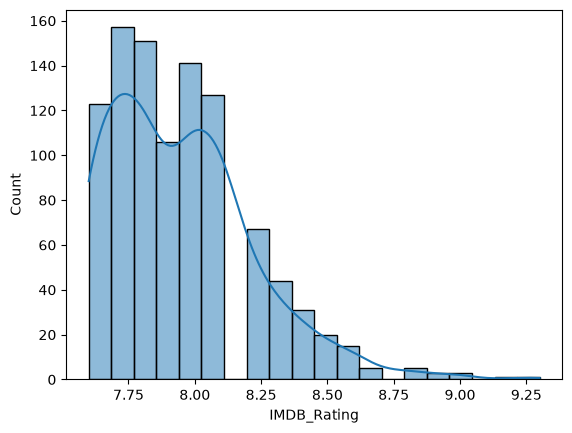

In [50]:
sns.histplot(df['IMDB_Rating'], bins = 20, kde = True);

In [51]:
df.columns

Index(['Series_Title', 'Released_Year', 'Certificate', 'Runtime', 'Genre',
       'IMDB_Rating', 'Overview', 'Meta_score', 'Director', 'Star1', 'Star2',
       'Star3', 'Star4', 'No_of_Votes', 'Gross', 'Gross_m'],
      dtype='str')

In [52]:
# plot the graph to check how many movies are there of each genre

In [56]:
df['Genre'].value_counts()

Genre
Drama                        85
Drama, Romance               37
Comedy, Drama                35
Comedy, Drama, Romance       31
Action, Crime, Drama         30
                             ..
Action, Adventure, Family     1
Action, Crime, Mystery        1
Animation, Drama, Romance     1
Drama, War, Western           1
Adventure, Comedy, War        1
Name: count, Length: 202, dtype: int64

In [57]:
# create another column -> main_genre -> have only the first genre value

In [59]:
df['Main_Genre'] = df['Genre'].str.split(',').str[0]
df['Main_Genre'];

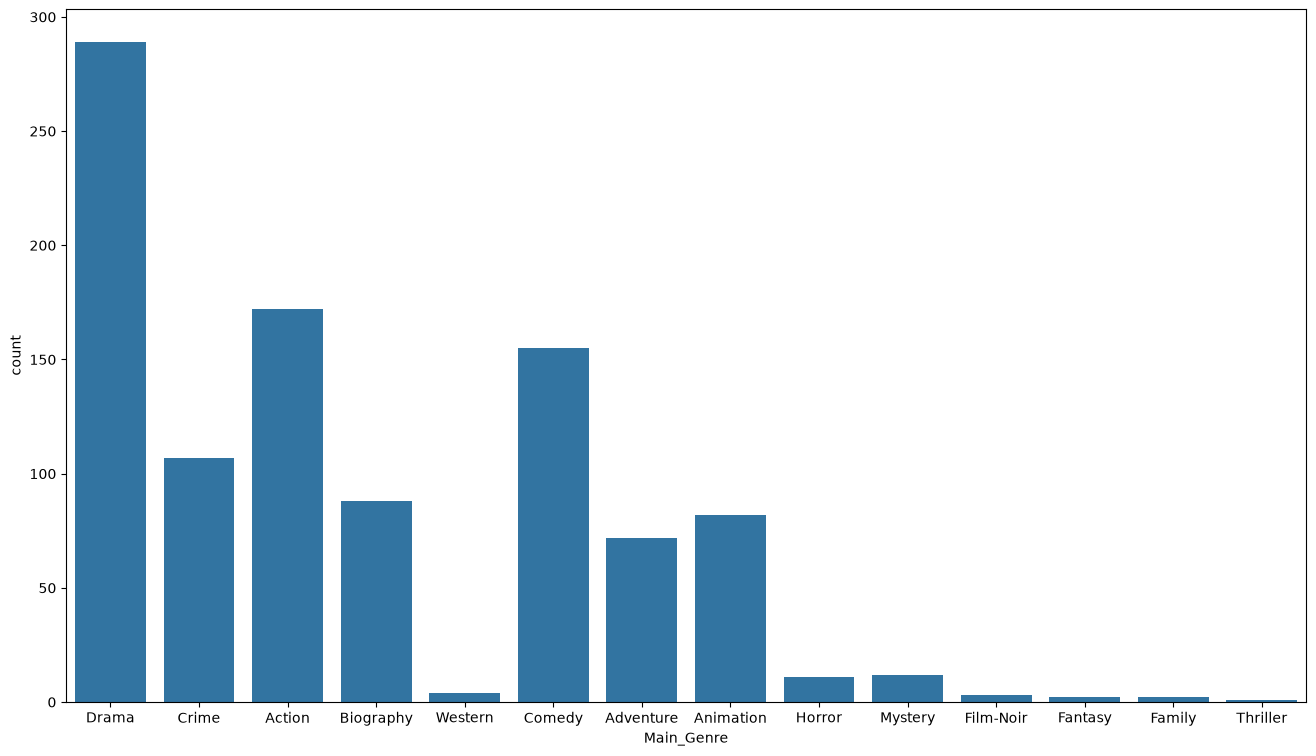

In [61]:
plt.figure(figsize=(16, 9))
sns.countplot(x = df['Main_Genre']);

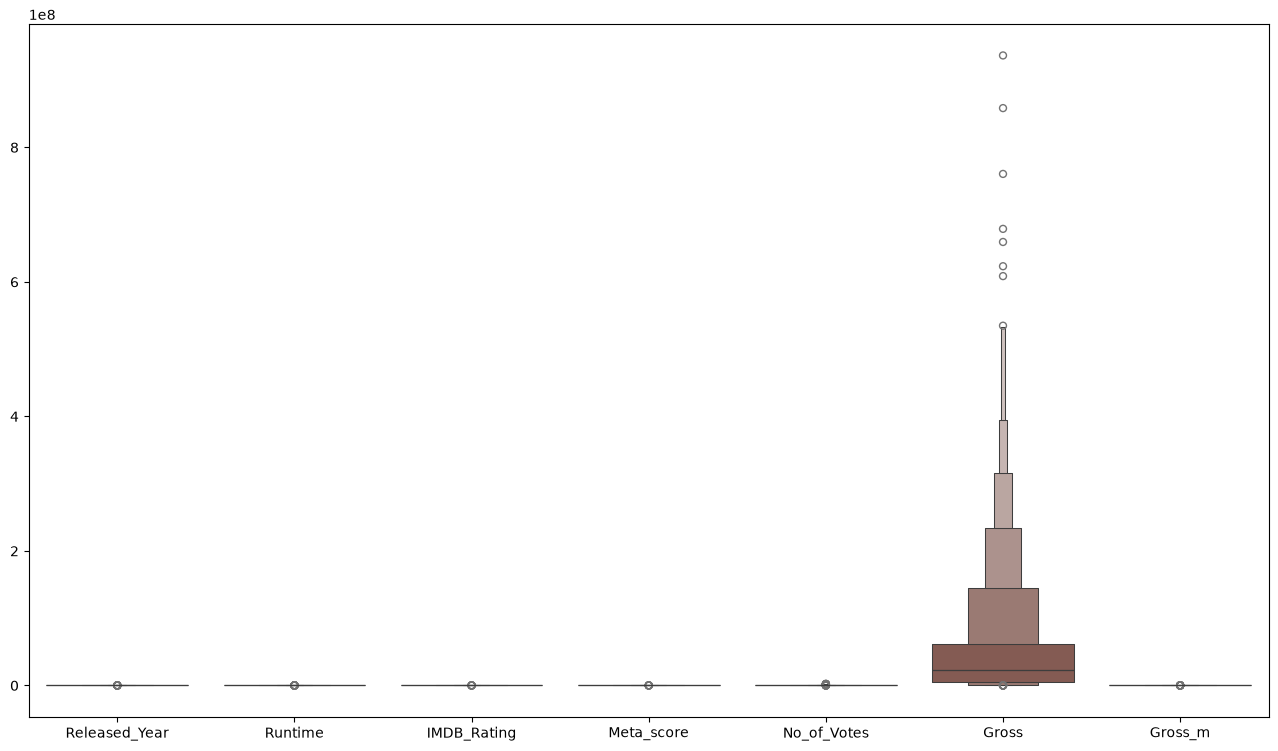

In [64]:
plt.figure(figsize=(16, 9))
sns.boxenplot(df);